# 15 · Modelos generalistas y el camino hacia la AGI

Este es un módulo de Neural Networks 1002. Supone los módulos de transformer ([módulo 09 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/)) y de GPT desde cero ([módulo 10 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/)); los módulos anteriores te dieron las piezas: neuronas, retropropagación, convoluciones, atención, aprendizaje por refuerzo, difusión, voz y agentes. Este módulo teórico de cierre pregunta qué ocurre cuando esas piezas se reúnen en **un solo modelo para muchas cosas**, y hasta dónde llega ese camino. Es deliberadamente sereno: para cada afirmación separamos **lo medido y publicado** de **lo especulativo**, y etiquetamos la especulación como tal. No damos **ni fechas ni probabilidades** para la inteligencia artificial general (AGI, del inglés artificial general intelligence), porque nadie tiene un método que las justifique.

Qué vas a construir: un pequeño transformer solo decodificador que lee **un único flujo de tokens** que mezcla una imagen de 8×8 (como 64 tokens) con palabras, y que usa los **mismos pesos** para clasificar, describir, generar una imagen a partir de una descripción y completar media imagen. Mides cada tarea, comparas con modelos de una sola tarea del mismo tamaño y luego haces un pequeño experimento de escalado: cuatro tamaños de modelo, dos semillas, una ley de potencia ajustada y una extrapolación a un tamaño que después sí entrenamos, para ver hasta dónde se puede confiar en esas extrapolaciones.

**Contenido**

1. Un modelo para todo: convertir cada modalidad en tokens
2. Escala y habilidades emergentes: lo que dicen y no dicen las leyes de escalado
3. Razonamiento: cadena de pensamiento, cómputo en tiempo de inferencia, recompensas verificables
4. Agentes y herramientas
5. El mundo físico: modelos del mundo y modelos visión-lenguaje-acción
6. Lo que todavía falta
7. ¿Qué significa "AGI" y por qué es difícil medirla?
8. Práctica: un transformer, cuatro tareas
9. Práctica: un pequeño experimento de escalado
10. Solo escala: argumentos a favor y en contra
11. Ideas clave, Ejercicios, Referencias

**Se apoya en**

| Módulo | Qué aportó | Uso aquí |
|---|---|---|
| [módulo 09 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/): transformer | atención, máscaras causales, bloques | el modelo de la sección 8 |
| [módulo 10 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/): LLM (GPT desde cero) | entrenamiento por siguiente token, sección de leyes de escalado | secciones 2, 8, 9 |
| [módulo 04 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/04-aprendizaje-por-refuerzo/): aprendizaje por refuerzo | recompensa, política, exploración | sección 3 (recompensas verificables) |
| [módulo 01 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/01-rlhf-y-alineacion/): RLHF y alineación | recompensa de preferencias, alineación | secciones 3 y 6 |
| [módulo 11 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/11-vision-mas-alla-de-la-clasificacion/): visión más allá de la clasificación | imágenes como cuadrículas, embeddings | sección 1 |
| [módulo 14 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/14-agentes-y-orquestacion/): agentes y orquestación | bucles de herramientas, supervisores | sección 4 |

Cursos relacionados: la idea de supervisor y bucle de herramientas de la sección 4 se enseña en el [curso de sistemas RAG, módulo 08 "el modelo supervisor"](https://rag-systems.academy.forwardforecasting.eu/es/08-el-modelo-supervisor/) (la portada del curso está [aquí](https://rag-systems.academy.forwardforecasting.eu/es/)), y los fundamentos de Python y PyTorch usados abajo están en [Python 1001](https://python.academy.forwardforecasting.eu/es/).

**Dónde el juguete difiere de los sistemas reales.** Todo lo que entrenamos tiene unos 30 mil parámetros, ve 1300 imágenes diminutas y corre unos cientos de pasos en una CPU. Los modelos generalistas reales tienen miles de millones de parámetros, billones de tokens de texto, imágenes y audio, y meses de tiempo de aceleradores. Nuestros resultados muestran el *mecanismo* (un flujo de tokens, un conjunto de pesos) y el *método* (medir, comparar, ajustar), no lo que puede hacer un sistema grande.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/15_modelos_generalistas_y_agi.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 2 minutos, con un pico de memoria de unos 1,1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. Un modelo para todo: convertir cada modalidad en tokens

Un transformer ([módulo 09 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/)) no sabe qué significan sus entradas. Convierte una secuencia de enteros (tokens) en embeddings, los mezcla con atención y predice el siguiente token. Por eso **todo lo que pueda escribirse como secuencia de símbolos discretos puede compartir un modelo**:

| Modalidad | Cómo se convierte en tokens | Ejemplo publicado |
|---|---|---|
| texto | piezas de subpalabras de un tokenizador | GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) |
| imágenes | divididas en parches, cada parche un vector (Vision Transformer, ViT) o un código de un libro de códigos aprendido (VQ-VAE (autoencoder variacional con cuantización vectorial)) | [ViT](https://arxiv.org/abs/2010.11929), [VQ-VAE](https://arxiv.org/abs/1711.00937), [DALL-E](https://arxiv.org/abs/2102.12092) |
| audio | tramas de espectrograma o códigos de un códec | [Whisper](https://arxiv.org/abs/2212.04356) (ver [módulo 06 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/06-generacion-de-audio-y-video/) y [módulo 07 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/07-voz-reconocimiento-sintesis-y-clonacion/)) |
| acciones | ángulos de articulaciones discretizados, pulsaciones de botones, llamadas a herramientas | [Gato](https://arxiv.org/abs/2205.06175) |

**Medido y publicado.** Gato usó un transformer con un solo conjunto de pesos para jugar a juegos de Atari, describir imágenes, conversar y controlar un brazo robótico real, con cada modalidad serializada en el mismo flujo de tokens. Chameleon ([Team, 2024](https://arxiv.org/abs/2405.09818)) entrenó desde cero un único modelo con texto e imágenes intercalados como tokens. CLIP ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)) y Flamingo ([Alayrac et al., 2022](https://arxiv.org/abs/2204.14198)) unen un codificador de visión con un modelo de lenguaje. Estos sistemas muestran que un modelo de secuencias compartido es *posible* y a menudo *cómodo*. No muestran que un solo modelo supere a un especialista en toda tarea: los especialistas siguen siendo comunes donde importan la exactitud o el coste.

La receta en todos es una **plantilla**: tokens especiales indican qué tarea se pide y el modelo continúa la secuencia. En la sección 8 se aplica la misma idea a escala de juguete:

```
clasificar : [64 tokens de imagen] <PREGUNTA> <etiqueta>
describir  : [64 tokens de imagen] <DESCRIPCION?> <palabra del dígito> <paridad> <tinta>
generar    : <DIBUJA> <palabra del dígito> <paridad> <tinta> [64 tokens de imagen]
completar  : [32 tokens superiores] <RELLENA> [32 tokens inferiores]
```

Fíjate en lo que cambia entre tareas: solo el **orden** de los mismos tipos de tokens. Por eso una arquitectura y una pérdida (predecir el siguiente token) sirven para las cuatro.

## 2. Escala y habilidades emergentes: lo que dicen y no dicen las leyes de escalado

[Módulo 10 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/) introdujo la idea de las leyes de escalado. Este es su contenido publicado, con precisión.

* **Kaplan et al. (2020)** ([arXiv 2001.08361](https://arxiv.org/abs/2001.08361)) midieron que la pérdida de prueba $L$ de los modelos de lenguaje baja como una **ley de potencia** del número de parámetros $N$, del tamaño del conjunto de datos $D$ y del cómputo $C$, cuando los otros factores no son el cuello de botella: aproximadamente $L(N) \approx (N_c / N)^{\alpha_N}$, donde $N_c$ y $\alpha_N$ (el exponente) son constantes ajustadas. Las tendencias se mantuvieron a lo largo de varios órdenes de magnitud.
* **Hoffmann et al. (2022)** ([arXiv 2203.15556](https://arxiv.org/abs/2203.15556)), el estudio "Chinchilla", volvieron a medir cómo repartir un presupuesto de cómputo fijo entre parámetros y tokens de entrenamiento y concluyeron que muchos modelos grandes de la época estaban **sub-entrenados**: parámetros y tokens deberían crecer más o menos juntos.
* **Lo que dicen las leyes**: la *pérdida media por siguiente token* sobre una distribución de datos fija es suave y predecible en $N$, $D$ y $C$ dentro del rango medido.
* **Lo que no dicen**: no dicen qué *habilidades* aparecen con qué pérdida, se ajustan a modelos pasados y no son leyes de la naturaleza, suponen datos de calidad constante (y la oferta de texto humano nuevo es finita, ver [Villalobos et al., 2022](https://arxiv.org/abs/2211.04325)), y no dicen nada de lo que ocurre fuera del rango medido.

**Habilidades emergentes.** [Wei et al. (2022)](https://arxiv.org/abs/2206.07682) describieron tareas cuya exactitud está cerca del azar en modelos pequeños y luego salta en los grandes. [Schaeffer et al. (2023)](https://arxiv.org/abs/2304.15004) argumentaron que muchos de esos saltos vienen de la **métrica**: una métrica de todo o nada como la coincidencia exacta convierte una mejora suave de la probabilidad por token en un salto aparente, y con una métrica continua las curvas suelen verse suaves. Ambos artículos son mediciones; el desacuerdo es de interpretación. Un resumen prudente: *la pérdida es suave y predecible; las habilidades concretas pueden verse repentinas o suaves según cómo se puntúen, y predecir una habilidad concreta a partir de una curva de pérdida es mucho menos fiable que predecir la pérdida misma.* La sección 9 te deja comprobar la primera mitad de esa frase en un juguete.

## 3. Razonamiento: cadena de pensamiento, cómputo en tiempo de inferencia, recompensas verificables

* **Cadena de pensamiento (CoT, del inglés chain of thought).** [Wei et al. (2022)](https://arxiv.org/abs/2201.11903) mostraron que dar a un modelo grande ejemplos resueltos que detallan los pasos intermedios mejora la exactitud en pruebas de aritmética y lógica. [Kojima et al. (2022)](https://arxiv.org/abs/2205.11916) vieron que incluso la instrucción "pensemos paso a paso" ayuda. Los tokens extra generados actúan como memoria de trabajo: cada paso condiciona el siguiente. La [autoconsistencia](https://arxiv.org/abs/2203.11171) muestrea varias cadenas y toma el voto mayoritario.
* **Cómputo en tiempo de inferencia.** En vez de solo agrandar el modelo (cómputo de entrenamiento), se gasta más cómputo al responder: cadenas más largas, más muestras, búsqueda. [Snell et al. (2024)](https://arxiv.org/abs/2408.03314) midieron que, en algunos problemas, más cómputo en inferencia puede sustituir a un modelo mayor, y que cómo gastarlo depende de la dificultad del problema.
* **Entrenamiento con recompensas verificables.** Cuando una respuesta puede **comprobarse automáticamente** (un resultado matemático, código que pasa pruebas unitarias), el aprendizaje por refuerzo ([módulo 04 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/04-aprendizaje-por-refuerzo/)) puede usar la comprobación como recompensa, sin un modelo de preferencias aprendido ([módulo 01 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/01-rlhf-y-alineacion/)). [DeepSeek-R1](https://arxiv.org/abs/2501.12948) informó que este tipo de entrenamiento hace aparecer en las salidas del modelo cadenas largas que se autoverifican.

**Salvedades (medidas, pero acotadas).** Las mejoras son mayores en dominios con un verificador barato. El razonamiento escrito no siempre es un relato fiel de cómo el modelo llegó a su respuesta, y la generalización de estas mejoras a dominios sin verificador es una pregunta de investigación abierta. Marcamos como *especulación* cualquier afirmación de que el entrenamiento con recompensas verificables se trasladará a tareas abiertas.

## 4. Agentes y herramientas

[Módulo 14 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/14-agentes-y-orquestacion/) construye un bucle de agente: el modelo propone una acción (una llamada a una herramienta), un programa la ejecuta, el resultado se añade al contexto y el bucle se repite. Dos ideas publicadas importan para el panorama generalista:

* **Las herramientas como acciones dentro del flujo de tokens.** [ReAct](https://arxiv.org/abs/2210.03629) intercala texto de razonamiento y acciones con herramientas; [Toolformer](https://arxiv.org/abs/2302.04761) entrena a un modelo para decidir cuándo llamar a una calculadora, un buscador o un traductor. Llamar a una herramienta son solo más tokens, y por eso el mismo modelo de secuencias puede manejarla (la idea de Gato de la sección 1).
* **Las herramientas corrigen debilidades sin reentrenar**: aritmética exacta, datos recientes, ejecución de código. El modelo debe elegir bien, y los errores se acumulan a lo largo de muchos pasos (sección 6).

El patrón de supervisor, donde un modelo reparte el trabajo entre especialistas y revisa los resultados, es la alternativa práctica a un único modelo monolítico; ver el [curso de sistemas RAG, módulo 08](https://rag-systems.academy.forwardforecasting.eu/es/08-el-modelo-supervisor/). Si el futuro es un gran generalista, o un generalista que orquesta especialistas y herramientas, es una **pregunta de diseño abierta**; los sistemas desplegados hoy mezclan ambos.

## 5. El mundo físico: modelos del mundo y modelos visión-lenguaje-acción

El texto es un registro de lo que la gente escribió. Un robot debe actuar en un mundo con física, retrasos y ruido. Dos líneas de trabajo lo abordan:

* **Modelos del mundo** aprenden a predecir cómo cambia el mundo. [Ha y Schmidhuber (2018)](https://arxiv.org/abs/1803.10122) entrenaron un modelo compacto de un entorno y después un controlador dentro de su "sueño"; [DreamerV3](https://arxiv.org/abs/2301.04104) aprende un modelo del mundo y planifica en su espacio latente, y se informó que funcionaba en muchas tareas distintas con un solo conjunto de hiperparámetros. [LeCun (2022)](https://openreview.net/forum?id=BZ5a1r-kVsf) propone una agenda de investigación (arquitecturas predictivas de incrustación conjunta) para aprender modelos del mundo; es un **artículo de posición**, no un resultado.
* **Modelos visión-lenguaje-acción (VLA)** ponen imágenes de cámara, una instrucción y acciones del robot en un solo flujo de tokens: [RT-2](https://arxiv.org/abs/2307.15818) ajusta un modelo visión-lenguaje para que emita acciones como tokens de texto, y [OpenVLA](https://arxiv.org/abs/2406.09246) es un modelo abierto de 7 mil millones de parámetros entrenado con datos de robots de [Open X-Embodiment](https://arxiv.org/abs/2310.08864), reunidos desde muchos laboratorios. Estos artículos informan mejoras al generalizar a objetos e instrucciones nuevos, con límites reales: los datos de robots son mucho más escasos que el texto, los errores en el mundo real son costosos y las tasas de éxito en tareas nuevas están muy por debajo del 100 por ciento.

El transformer multitarea de la sección 8 es, estructuralmente, una miniatura de esta idea: imágenes, palabras y "acciones" (aquí, los tokens de respuesta) en un solo flujo.

## 6. Lo que todavía falta

Lo siguiente son limitaciones documentadas de los sistemas actuales. Para cada una, si el escalado por sí solo la elimina es *discutido* (sección 10).

| Carencia | Qué se ha medido | Enlace |
|---|---|---|
| **Alucinación** | afirmaciones fluidas pero falsas; estudiadas en muchas tareas; un argumento teórico dice que los modelos calibrados entrenados con hechos vistos una sola vez deben producir algunos errores | [Ji et al., 2023](https://arxiv.org/abs/2202.03629), [Kalai y Vempala, 2023](https://arxiv.org/abs/2311.14648) |
| **Planificación a largo plazo** | los modelos rinden mal en pruebas de planificación sin ayuda externa; el rendimiento cae al crecer la profundidad composicional | [Valmeekam et al., 2022](https://arxiv.org/abs/2206.10498), [Dziri et al., 2023](https://arxiv.org/abs/2305.18654) |
| **Uso de contexto largo** | la información en medio de una entrada larga se usa con menos fiabilidad | [Liu et al., 2023](https://arxiv.org/abs/2307.03172) |
| **Aprender con pocos ejemplos** | las personas generalizan a partir de uno o dos ejemplos; las redes profundas suelen necesitar muchos más (el aprendizaje en contexto acorta la brecha en parte) | [Lake et al., 2016](https://arxiv.org/abs/1604.00289) |
| **Aprendizaje continuo** | aprender algo nuevo puede sobrescribir lo anterior (olvido catastrófico); los modelos desplegados quedan congelados entre versiones | [Kirkpatrick et al., 2017](https://arxiv.org/abs/1612.00796) |
| **Alineación** | especificar y verificar lo que queremos; recompensas mal especificadas ([módulo 01 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/01-rlhf-y-alineacion/)) | [Amodei et al., 2016](https://arxiv.org/abs/1606.06565), [Ouyang et al., 2022](https://arxiv.org/abs/2203.02155) |
| **Evaluación** | las pruebas se saturan y se filtran a los datos de entrenamiento (sección 7) | [Liang et al., 2022 (HELM)](https://arxiv.org/abs/2211.09110), [Zhang et al., 2024](https://arxiv.org/abs/2405.00332) |

Otro riesgo publicado para el camino del escalado es devolver la salida de los modelos al entrenamiento: [Shumailov et al. (2023)](https://arxiv.org/abs/2305.17493) mostraron en experimentos controlados que los modelos entrenados recursivamente con datos generados pierden las colas de la distribución.

## 7. ¿Qué significa "AGI" y por qué es difícil medirla?

**No hay una definición acordada.** Tres publicadas, con objetivos distintos:

* **Niveles de capacidad.** [Morris et al. (2023), "Levels of AGI"](https://arxiv.org/abs/2311.02462) proponen clasificar los sistemas por **rendimiento** (percentil de adultos cualificados) y **generalidad** (amplitud de tareas), en niveles de "emergente" a "sobrehumano", y tratan la autonomía por separado. Es un marco de discusión, no una medición de ningún sistema.
* **Eficiencia de adquisición de habilidades.** [Chollet (2019), "On the Measure of Intelligence"](https://arxiv.org/abs/1911.01547) sostiene que la inteligencia debe medirse por la eficiencia con que un sistema adquiere **habilidades nuevas** dados su conocimiento previo y su experiencia, no por la destreza en tareas para las que pudo entrenarse. Su **Abstraction and Reasoning Corpus (ARC)** ([repositorio del benchmark](https://github.com/fchollet/ARC-AGI), [sitio del premio](https://arcprize.org/)) plantea pequeños acertijos de cuadrícula, cada uno con pocos ejemplos, diseñados para requerir reglas nuevas.
* **Inteligencia universal.** [Legg y Hutter (2007)](https://arxiv.org/abs/0712.3329) definen la inteligencia como el rendimiento esperado en todos los entornos computables, ponderados por su simplicidad: una fórmula limpia que no puede calcularse, así que orienta el pensamiento en lugar de servir de prueba.

Un ancla histórica más amplia es [Turing (1950)](https://doi.org/10.1093/mind/LIX.236.433), que sustituyó "¿pueden pensar las máquinas?" por un juego de imitación. [Bubeck et al. (2023)](https://arxiv.org/abs/2303.12712) describieron un GPT-4 temprano como muestra de "chispas" de inteligencia general, una afirmación leída de forma muy distinta por distintos investigadores.

**Por qué medir es difícil.**

1. **Saturación.** Las pruebas se construyen difíciles y luego los modelos mejoran hasta que dejan de ser informativas; hacen falta otras nuevas ([HELM](https://arxiv.org/abs/2211.09110) defiende informes amplios y holísticos).
2. **Contaminación.** Los elementos de prueba pueden aparecer en los datos de entrenamiento; [Zhang et al. (2024)](https://arxiv.org/abs/2405.00332) construyeron un conjunto nuevo de matemáticas de primaria y midieron que algunos modelos puntúan notablemente menos que en el público, señal de sobreajuste al conjunto público.
3. **La elección de métrica** cambia la historia (sección 2).
4. **Las definiciones se separan.** Un sistema puede alcanzar un alto nivel de *rendimiento* en muchas tareas y fallar la prueba de *eficiencia* de Chollet, y al revés. Cuál importa es un juicio de valor, no un experimento.
5. **Las personas son una referencia móvil y heterogénea**, y "adulto cualificado" depende del dominio.

Por todo esto, cualquier afirmación de que "la AGI llegará en el año X" o "con probabilidad p" mezcla una definición disputada con un pronóstico imposible de medir. Este notebook no da ninguna de las dos.

## 8. Práctica: un transformer, cuatro tareas

**Datos.** El conjunto digits de scikit-learn ([Alpaydin y Kaynak, UCI Optical Recognition of Handwritten Digits](https://archive.ics.uci.edu/dataset/80), licencia CC BY 4.0, incluido en [scikit-learn](https://jmlr.org/papers/v12/pedregosa11a.html), sin descarga). Cada imagen es de 8×8 con grises de 0 a 16. **Cuantizamos a 16 niveles de gris** (valores 0 a 15) para que cada píxel sea un token: 64 tokens de imagen. Separamos 1300 imágenes para entrenar y 497 para probar.

**Palabras.** Una descripción son tres tokens: una palabra de dígito (`zero` ... `nine`), una de paridad (`even`/`odd`) y una de tinta (`light`/`heavy`, según si la tinta total está por debajo o por encima de la mediana de entrenamiento). Vocabulario: 16 tokens de gris, 10 palabras de dígito, 2 de paridad, 2 de tinta, 4 tokens de tarea y uno de relleno, 35 en total.

**Las cuatro plantillas** (sección 1). El entrenamiento usa predicción del siguiente token, contando la pérdida **solo en los tokens de respuesta** de cada plantilla (la etiqueta, la descripción, la imagen generada, la mitad inferior), promediada por secuencia para que una respuesta de un token pese lo mismo que una de 64. La cuarta tarea, **completar**, es la tarea mixta que elegimos: dada la mitad superior de una imagen, producir la inferior. Exige que el modelo entienda la imagen (para saber qué dígito es) y que genere (para dibujar el resto).

**Medidas.** Clasificación: exactitud. Descripción: coincidencia exacta de las tres palabras (y de la palabra del dígito sola). Generación: entrenamos un **clasificador independiente** (un pequeño perceptrón multicapa de scikit-learn que el transformer nunca ve) con las imágenes reales de entrenamiento y reportamos con qué frecuencia reconoce el *dígito pedido* en las imágenes generadas. Completar: con qué frecuencia ese clasificador reconoce el dígito verdadero en la imagen completada, y el error absoluto medio en niveles de gris de la mitad inferior. Para comparar entrenamos **modelos de una sola tarea con la misma arquitectura y tamaño, con el mismo número de pasos**: el generalista reparte su cómputo entre cuatro tareas, cada modelo de una tarea lo gasta en una.

In [1]:
import warnings, os, time
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPClassifier

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
T0 = time.time()

digits = load_digits()
Xq = np.minimum(digits.data.astype(int), 15)          # 16 niveles de gris, 64 valores por imagen
y = digits.target
perm = np.random.default_rng(0).permutation(len(y))
tr, te = perm[:1300], perm[1300:]
ink = Xq.sum(1); med = np.median(ink[tr]); heavy = (ink > med).astype(int)

# vocabulario: 0-15 grises, 16-25 palabras de dígito, 26-27 paridad, 28-29 tinta, luego tokens de tarea y relleno
DW, PAR, INK = 16, 26, 28
QCLS, QCAP, QGEN, QFILL, PAD = 30, 31, 32, 33, 34
V, L = 35, 68
WORDS = ["zero","one","two","three","four","five","six","seven","eight","nine"]

def seq(i, task):
    img = list(Xq[i]); cap = [DW + y[i], PAR + y[i] % 2, INK + heavy[i]]
    if task == 0:   s = img + [QCLS, DW + y[i]]                  # clasificar
    elif task == 1: s = img + [QCAP] + cap                       # describir
    elif task == 2: s = [QGEN] + cap + img                       # generar imagen a partir de la descripción
    else:           s = img[:32] + [QFILL] + img[32:]            # completar la mitad inferior
    return s + [PAD] * (L - len(s))

ANS = {0: range(65, 66), 1: range(65, 68), 2: range(4, 68), 3: range(33, 65)}   # posiciones de la respuesta
def build(idx, tasks):
    x = torch.tensor([seq(i, t) for t in tasks for i in idx])
    m = torch.zeros_like(x, dtype=torch.bool)
    for k, t in enumerate(tasks):
        m[k*len(idx):(k+1)*len(idx), list(ANS[t])] = True
    return x, m

print("tokens de descripción de ejemplo:", [WORDS[y[0]], ["even","odd"][y[0] % 2], ["light","heavy"][heavy[0]]])
print("longitud de secuencia", L, "| imágenes de entrenamiento", len(tr), "| imágenes de prueba", len(te))

tokens de descripción de ejemplo: ['zero', 'even', 'light']
longitud de secuencia 68 | imágenes de entrenamiento 1300 | imágenes de prueba 497


In [2]:
class Block(nn.Module):
    def __init__(s, dm, nh):
        super().__init__(); s.nh = nh
        s.l1 = nn.LayerNorm(dm); s.qkv = nn.Linear(dm, 3*dm); s.o = nn.Linear(dm, dm)
        s.l2 = nn.LayerNorm(dm); s.ff = nn.Sequential(nn.Linear(dm, 4*dm), nn.GELU(), nn.Linear(4*dm, dm))
    def forward(s, x):
        B, T, D = x.shape
        q, k, v = s.qkv(s.l1(x)).view(B, T, 3, s.nh, D // s.nh).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D)
        x = x + s.o(a)
        return x + s.ff(s.l2(x))

class Net(nn.Module):                       # transformer solo decodificador, como en los módulos 09 y 10 de Neural Networks 1001
    def __init__(s, dm, nl, nh=4):
        super().__init__()
        s.te = nn.Embedding(V, dm); s.pe = nn.Embedding(L, dm)
        s.blocks = nn.ModuleList([Block(dm, nh) for _ in range(nl)])
        s.ln = nn.LayerNorm(dm); s.head = nn.Linear(dm, V)
    def forward(s, x):
        h = s.te(x) + s.pe(torch.arange(x.shape[1]))
        for b in s.blocks: h = b(h)
        return s.head(s.ln(h))

def nparams(m): return sum(p.numel() for p in m.parameters())

def lossf(m, xm):
    # entropía cruzada del siguiente token solo en los tokens de respuesta, promediada por secuencia y luego por lote
    x, mk = xm; lg = m(x[:, :-1]); t = x[:, 1:]; mk = mk[:, 1:]
    ce = F.cross_entropy(lg.reshape(-1, V), t.reshape(-1), reduction="none").view(t.shape) * mk
    return (ce.sum(1) / mk.sum(1)).mean()

def train(tasks, dm=32, nl=2, steps=500, bs=32, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    m = Net(dm, nl); data, dmask = build(tr, tasks)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.05)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    g = torch.Generator().manual_seed(seed)
    for s in range(steps):
        ix = torch.randint(len(data), (bs,), generator=g)
        l = lossf(m, (data[ix], dmask[ix])); opt.zero_grad(); l.backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
    return m

@torch.no_grad()
def test_loss(m, tasks):
    m.eval(); return lossf(m, build(te, tasks)).item()

# el juez independiente: nunca forma parte del transformer, entrenado solo con imágenes reales de entrenamiento
clf = MLPClassifier((64,), max_iter=400, random_state=0).fit(Xq[tr], y[tr])
print("clasificador independiente, exactitud en imágenes reales de prueba:", round(clf.score(Xq[te], y[te]), 3))

clasificador independiente, exactitud en imágenes reales de prueba: 0.976


In [3]:
@torch.no_grad()
def extend(m, prefix, n, allowed, temperature, g):
    # continúa cada prefijo n tokens, restringido a los ids permitidos (temperatura 0 = voraz)
    P = prefix.shape[1]
    x = torch.cat([prefix, torch.full((len(prefix), L - P), PAD)], 1)
    ban = torch.full((V,), float("-inf")); ban[allowed] = 0
    for k in range(n):
        lg = m(x[:, :P + k])[:, -1] + ban
        if temperature == 0: nxt = lg.argmax(-1)
        else: nxt = torch.multinomial(F.softmax(lg / temperature, -1), 1, generator=g)[:, 0]
        x[:, P + k] = nxt
    return x[:, P:P + n]

def evaluate(m, tasks, ngen=200, temp=0.5, seed=0):
    m.eval(); g = torch.Generator().manual_seed(seed); out = {}
    img = torch.tensor(Xq[te]); N = len(te); digit = torch.tensor(y[te])
    cap = torch.stack([DW + digit, PAR + digit % 2, INK + torch.tensor(heavy[te])], 1)
    col = lambda t: torch.full((N, 1), t)
    if 0 in tasks:
        p = extend(m, torch.cat([img, col(QCLS)], 1), 1, list(range(DW, DW + 10)), 0, g)[:, 0]
        out["exactitud de clasificación"] = (p == DW + digit).float().mean().item()
    if 1 in tasks:
        p = extend(m, torch.cat([img, col(QCAP)], 1), 3, list(range(DW, INK + 2)), 0, g)
        out["descripción: coincidencia exacta"] = (p == cap).all(1).float().mean().item()
        out["descripción: palabra del dígito"] = (p[:, 0] == cap[:, 0]).float().mean().item()
    if 2 in tasks:
        pre = torch.cat([torch.full((ngen, 1), QGEN), cap[:ngen]], 1)
        im = extend(m, pre, 64, list(range(16)), temp, g)
        out["generada: reconocida como el dígito pedido"] = (clf.predict(im.numpy()) == digit[:ngen].numpy()).mean()
        out["_gen"] = im.numpy()
    if 3 in tasks:
        bot = extend(m, torch.cat([img[:, :32], col(QFILL)], 1), 32, list(range(16)), 0, g)
        full = torch.cat([img[:, :32], bot], 1).numpy()
        out["completar: dígito verdadero reconocido"] = (clf.predict(full) == y[te]).mean()
        out["completar: error de gris (mitad inferior)"] = (bot - img[:, 32:]).abs().float().mean().item()
        out["_fill"] = full
    return out

**Puntos de referencia para poder leer los números.** El azar en clasificación es del 10 por ciento. Para completar probamos también la completación más perezosa posible, copiar la **mitad inferior media de las imágenes de entrenamiento** (sin modelo): eso muestra cuánto de la puntuación de completar viene del modelo aprendido y cuánto de la mitad superior visible. El techo de cualquier puntuación juzgada es la exactitud del clasificador independiente en imágenes reales (impresa arriba).

Ahora entrenamos el **generalista** (las cuatro plantillas mezcladas, 500 pasos) y **cuatro modelos de una sola tarea** (misma arquitectura, 500 pasos cada uno, una plantilla). Ambos tienen el mismo cómputo: cada modelo da el mismo número de pasos de gradiente con el mismo tamaño de lote. Esto tarda unos minutos en una CPU.

In [4]:
CFG = dict(dm=32, nl=2, steps=500, bs=32, lr=3e-3, seed=0)
NAMES = ["classify", "caption", "generate", "complete"]
t = time.time(); gen_model = train([0, 1, 2, 3], **CFG)
print(f"generalista: {nparams(gen_model):,} parámetros, entrenado en {time.time()-t:.0f} s")
singles = {}
for k in range(4):
    t = time.time(); singles[k] = train([k], **CFG); print(f"modelo de una tarea '{NAMES[k]}' entrenado en {time.time()-t:.0f} s")

t = time.time()
res_gen = evaluate(gen_model, [0, 1, 2, 3])
res_single = {k: evaluate(singles[k], [k]) for k in range(4)}
print(f"evaluación: {time.time()-t:.0f} s")

# completación más perezosa: la mitad inferior media de las imágenes de entrenamiento, redondeada
mean_bot = np.rint(Xq[tr][:, 32:].mean(0)).astype(int)
lazy = np.concatenate([Xq[te][:, :32], np.tile(mean_bot, (len(te), 1))], 1)
lazy_acc = (clf.predict(lazy) == y[te]).mean()

rows = []
for k in range(4):
    for name, v in res_single[k].items():
        if name[0] != "_": rows.append((name, res_gen[name], v))
print(f"\n{'métrica':48s} {'generalista':>11s} {'una tarea':>12s}")
for name, a, b in rows: print(f"{name:48s} {a:11.3f} {b:12.3f}")
print(f"{'completar copiando la mitad inferior media':48s} {'':11s} {lazy_acc:12.3f}   (sin modelo)")

generalista: 29,923 parámetros, entrenado en 73 s


modelo de una tarea 'classify' entrenado en 80 s


modelo de una tarea 'caption' entrenado en 40 s


modelo de una tarea 'generate' entrenado en 37 s


modelo de una tarea 'complete' entrenado en 42 s


evaluación: 29 s

métrica                                          generalista    una tarea
exactitud de clasificación                             0.791        0.903
descripción: coincidencia exacta                       0.640        0.839
descripción: palabra del dígito                        0.793        0.895
generada: reconocida como el dígito pedido             0.080        0.615
completar: dígito verdadero reconocido                 0.396        0.565
completar: error de gris (mitad inferior)              5.246        3.770
completar copiando la mitad inferior media                          0.539   (sin modelo)


**Leer la tabla.** El error estándar de una exactitud medida con 497 imágenes de prueba es de unos 1,5 a 2 puntos, y entrenamos **una semilla** por modelo, así que diferencias de pocos puntos entre el generalista y un modelo de una tarea **no** son evidencia de una brecha real en ningún sentido. Aquí la mayoría de las diferencias son mucho mayores que eso, pero las menores (por ejemplo en completar) deben leerse teniendo en cuenta ese ruido. La sección 9 añade semillas para la pérdida.

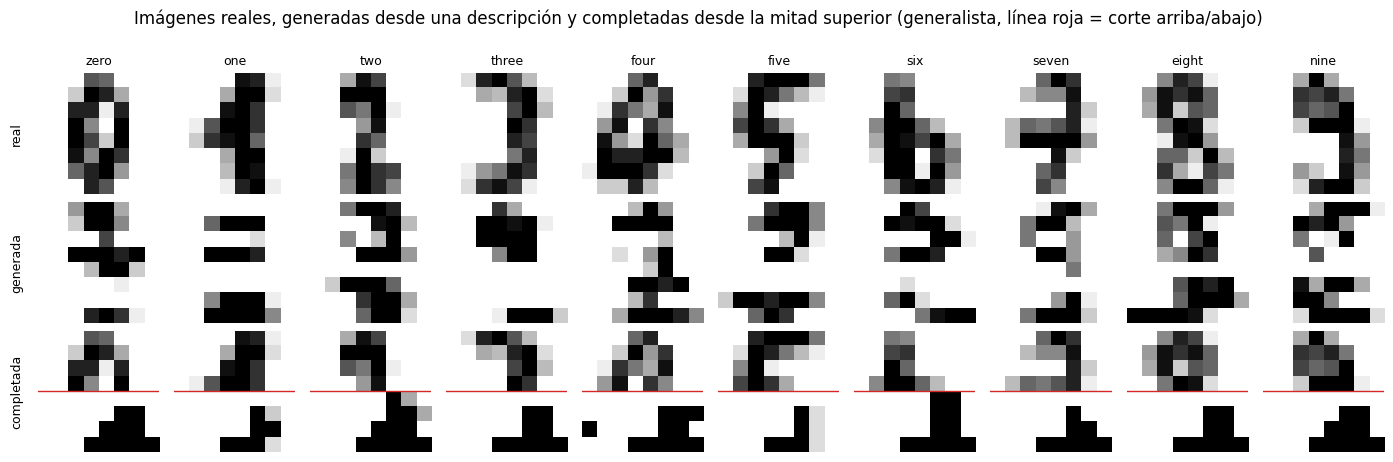

In [5]:
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
gen_imgs = res_gen["_gen"]; fills = res_gen["_fill"]
shown = {}
for j in range(200):
    d = int(y[te][j]) if j < 200 else None
    if d not in shown: shown[d] = j
for d in range(10):
    j = shown[d]
    axes[0, d].imshow(Xq[te][j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=15)
    axes[1, d].imshow(gen_imgs[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=15)
    axes[2, d].imshow(fills[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=15)
    axes[2, d].axhline(3.5, color="tab:red", lw=1)
    for r in range(3): axes[r, d].axis("off")
    axes[0, d].set_title(WORDS[d], fontsize=9)
axes[0, 0].text(-1.5, 3.5, "real", rotation=90, va="center", ha="right", fontsize=9)
axes[1, 0].text(-1.5, 3.5, "generada", rotation=90, va="center", ha="right", fontsize=9)
axes[2, 0].text(-1.5, 3.5, "completada", rotation=90, va="center", ha="right", fontsize=9)
plt.suptitle("Imágenes reales, generadas desde una descripción y completadas desde la mitad superior (generalista, línea roja = corte arriba/abajo)", y=1.0)
plt.tight_layout(); plt.show()

**Lectura: qué muestran los números.** Con el mismo tamaño de modelo y el mismo número de pasos de gradiente, el generalista fue **peor que los modelos de una tarea en todas las tareas** en esta ejecución: clasificación cerca del 79 por ciento frente al 90, coincidencia exacta de la descripción cerca del 64 frente al 84, completar cerca del 40 frente al 57 por ciento reconocido. La mayor brecha está en **generar una imagen a partir de una descripción**: las imágenes del generalista se reconocieron como el dígito pedido cerca del 8 por ciento de las veces, es decir en el azar o por debajo (10 por ciento), mientras que el generador de una tarea llegó a cerca del 62 por ciento (el techo que fija el juez en imágenes reales es del 97,6 por ciento, así que incluso las imágenes del especialista son solo en parte reconocibles). En la figura, las imágenes del generalista (fila central) son trazos oscuros sin forma clara de dígito, y sus completaciones (fila inferior, bajo la línea roja; la mitad superior es real) son casi la misma mancha sea cual sea el dígito. Completar requiere una salvedad: copiar la mitad inferior media, sin ningún modelo, ya da cerca del 54 por ciento, así que el modelo de completar de una tarea (cerca del 57 por ciento) aporta poco sobre la mitad superior visible con este tiempo de entrenamiento.

Lo que esto **no** muestra: que los generalistas sean peores en general. La comparación tiene el mismo cómputo, así que el generalista recibió cerca de una cuarta parte de la señal de gradiente por tarea; el modelo tiene solo 30 mil parámetros, así que hay poca capacidad sobrante para compartir; y 500 pasos están lejos de la convergencia. Con este experimento no podemos separar la *interferencia entre tareas* del simple *sub-entrenamiento* (los Ejercicios 2 y 3 son el siguiente paso). Lo que sí muestra es el equilibrio medido a escala de juguete: compartir pesos no es gratis, y las afirmaciones de la literatura de que mezclar tareas ayuda se apoyan en modelos mucho mayores y entrenamientos mucho más largos. La brecha en generación recuerda además que la plantilla más difícil (una respuesta de 64 tokens a partir de una indicación de tres palabras) es la primera que sufre cuando escasean la capacidad o el entrenamiento.

**Sistemas reales.** Un modelo multimodal real puede probarse en pocas líneas con un punto de control preentrenado, pero requiere una descarga de cientos de megabytes y mucho más tiempo de CPU que el presupuesto de este módulo, así que la celda siguiente se **muestra, no se ejecuta**. Pide a un modelo abierto de visión-lenguaje que describa una imagen y responda una pregunta sobre ella, que son las mismas dos plantillas (descripción, pregunta-respuesta) de nuestro juguete, a una escala enormemente mayor.

```python
# NO SE EJECUTA en este notebook (requiere `pip install transformers pillow` y una descarga de ~1 GB).
from transformers import pipeline
from PIL import Image
captioner = pipeline("image-to-text", model="Salesforce/blip-image-captioning-base")
print(captioner(Image.open("photo.jpg")))                      # plantilla de descripción
vqa = pipeline("visual-question-answering", model="dandelin/vilt-b32-finetuned-vqa")
print(vqa(image=Image.open("photo.jpg"), question="How many people are in the picture?"))
```

Los modelos son [BLIP](https://arxiv.org/abs/2201.12086) y [ViLT](https://arxiv.org/abs/2102.03334), ambos abiertos y pequeños para los estándares actuales.

## 9. Práctica: un pequeño experimento de escalado

Ahora el experimento detrás de la sección 2. Entrenamos el generalista (las cuatro plantillas) en **cinco tamaños** (de unos 2 mil a 65 mil parámetros) con **dos semillas**, 300 pasos cada uno, y medimos la **pérdida de prueba** (entropía cruzada de los tokens de respuesta sobre las 497 imágenes de prueba, las cuatro plantillas). Luego ajustamos una ley de potencia $L = a\,N^{-b}$ ($N$ = parámetros, $a$ y $b$ constantes ajustadas, $b$ el exponente) por mínimos cuadrados sobre $\log L$ frente a $\log N$, usando **solo los cuatro tamaños menores**. Predecimos la pérdida del quinto tamaño, el mayor, con un intervalo de predicción del 90 por ciento, y solo entonces la comparamos con la pérdida que realmente medimos allí. Dos semillas dan ocho puntos para el ajuste.

In [6]:
SIZES = [(8, 1), (16, 1), (24, 2), (32, 2), (40, 3)]      # (ancho, capas); el último se deja fuera del ajuste
SEEDS = [0, 1]
t = time.time()
scale = {}   # (índice de tamaño, semilla) -> (parámetros, pérdida de prueba)
for i, (dm, nl) in enumerate(SIZES):
    for s in SEEDS:
        m = train([0, 1, 2, 3], dm=dm, nl=nl, steps=300, bs=32, lr=3e-3, seed=s)
        scale[(i, s)] = (nparams(m), test_loss(m, [0, 1, 2, 3]))
    print(f"tamaño {i}: ancho {dm}, capas {nl}, {scale[(i, 0)][0]:,} parámetros, "
          f"pérdida por semilla {[round(scale[(i, s)][1], 3) for s in SEEDS]}")
print(f"las ejecuciones de escalado tardaron {time.time()-t:.0f} s")

tamaño 0: ancho 8, capas 1, 2,027 parámetros, pérdida por semilla [1.934, 1.949]


tamaño 1: ancho 16, capas 1, 5,555 parámetros, pérdida por semilla [1.76, 1.727]


tamaño 2: ancho 24, capas 2, 17,843 parámetros, pérdida por semilla [1.428, 1.422]


tamaño 3: ancho 32, capas 2, 29,923 parámetros, pérdida por semilla [1.327, 1.232]


tamaño 4: ancho 40, capas 3, 64,795 parámetros, pérdida por semilla [1.199, 1.141]
las ejecuciones de escalado tardaron 508 s


ajuste con 4 tamaños x 2 semillas: L = 6.49 * N^(-0.156), R^2 = 0.971
predicción en N = 64,795: 1.155  (intervalo de predicción del 90% 1.067 to 1.250)
medido en N = 64,795: 1.199 and 1.141 (dos semillas)
valores medidos dentro del intervalo: True


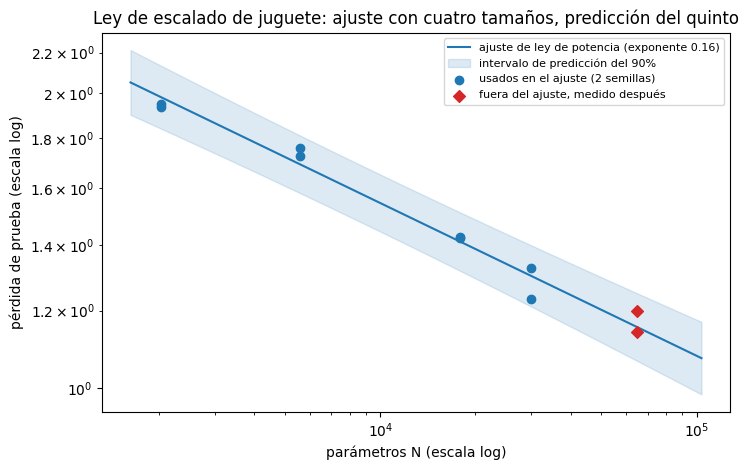

In [7]:
from scipy import stats
fit_pts = [(scale[(i, s)][0], scale[(i, s)][1]) for i in range(4) for s in SEEDS]
N = np.array([p[0] for p in fit_pts], float); Lo = np.array([p[1] for p in fit_pts])
lx, ly = np.log(N), np.log(Lo)
slope, icpt, r, _, _ = stats.linregress(lx, ly)
b, a = -slope, np.exp(icpt)
res = ly - (icpt + slope * lx); s_res = np.sqrt((res ** 2).sum() / (len(lx) - 2))
Nstar = scale[(4, 0)][0]; x0 = np.log(Nstar)
se_pred = s_res * np.sqrt(1 + 1 / len(lx) + (x0 - lx.mean()) ** 2 / ((lx - lx.mean()) ** 2).sum())
tq = stats.t.ppf(0.95, len(lx) - 2)
pred = np.exp(icpt + slope * x0); lo, hi = pred * np.exp(-tq * se_pred), pred * np.exp(tq * se_pred)
actual = [scale[(4, s)][1] for s in SEEDS]

print(f"ajuste con 4 tamaños x 2 semillas: L = {a:.2f} * N^(-{b:.3f}), R^2 = {r**2:.3f}")
print(f"predicción en N = {Nstar:,}: {pred:.3f}  (intervalo de predicción del 90% {lo:.3f} to {hi:.3f})")
print(f"medido en N = {Nstar:,}: {actual[0]:.3f} and {actual[1]:.3f} (dos semillas)")
inside = all(lo <= v <= hi for v in actual)
print("valores medidos dentro del intervalo:", inside)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
xs = np.logspace(np.log10(N.min() * 0.8), np.log10(Nstar * 1.6), 100)
ax.plot(xs, a * xs ** (-b), color="tab:blue", label=f"ajuste de ley de potencia (exponente {b:.2f})")
band_lo = np.exp(icpt + slope * np.log(xs)) * np.exp(-tq * s_res * np.sqrt(1 + 1/len(lx) + (np.log(xs) - lx.mean()) ** 2 / ((lx - lx.mean()) ** 2).sum()))
band_hi = np.exp(icpt + slope * np.log(xs)) * np.exp(tq * s_res * np.sqrt(1 + 1/len(lx) + (np.log(xs) - lx.mean()) ** 2 / ((lx - lx.mean()) ** 2).sum()))
ax.fill_between(xs, band_lo, band_hi, color="tab:blue", alpha=0.15, label="intervalo de predicción del 90%")
ax.scatter(N, Lo, color="tab:blue", zorder=3, label="usados en el ajuste (2 semillas)")
ax.scatter([Nstar] * 2, actual, color="tab:red", marker="D", zorder=3, label="fuera del ajuste, medido después")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("parámetros N (escala log)"); ax.set_ylabel("pérdida de prueba (escala log)")
ax.set_title("Ley de escalado de juguete: ajuste con cuatro tamaños, predicción del quinto")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura: qué muestran los números.** La pérdida de prueba bajó suavemente al crecer el modelo, de cerca de 1,9 con 2 mil parámetros a cerca de 1,2 con 65 mil, y las dos semillas coinciden bastante en los tamaños pequeños (difieren hasta cerca de 0,1 con 30 mil parámetros, un recordatorio de que el ruido de semilla no es despreciable). El ajuste de ley de potencia sobre los cuatro tamaños menores tiene un exponente de cerca de 0,16 y un $R^2$ de cerca de 0,97. Predijo una pérdida de cerca de 1,16 con 65 mil parámetros con un intervalo del 90 por ciento de cerca de 1,07 a 1,25, y los dos valores medidos (cerca de 1,20 y 1,14) caen **dentro** del intervalo. Así que en este juguete una extrapolación corta funcionó. Ojo con cuánto vale eso: extrapolamos solo un factor de cerca de 2 en tamaño, con ocho puntos; el intervalo es ancho (más o menos un 8 por ciento); el ancho y la profundidad crecieron juntos, así que el eje x mezcla dos formas de hacerse mayor; todos los modelos entrenaron los mismos 300 pasos, así que los mayores pueden simplemente aprender más rápido por paso en vez de ser mejores en la convergencia; y nuestro exponente no dice nada de los modelos de lenguaje, cuyos exponentes se miden con datos completamente distintos.

**¿Hasta dónde se puede confiar en esas extrapolaciones?** Las leyes de escalado publicadas se ajustan con ejecuciones que abarcan muchos órdenes de magnitud y se usan para extrapolar uno o dos órdenes de magnitud, donde se han contrastado con entrenamientos posteriores (ver Kaplan et al. y Hoffmann et al. arriba). Aun así: (1) el intervalo de una regresión cubre solo el **ruido dentro del rango medido**, no la posibilidad de que la tendencia se doble fuera de él (nuestro juguete tiene un conjunto de datos finito, así que los modelos mayores acabarán sobreajustando y la curva debe aplanarse); (2) la forma ajustada (una ley de potencia pura sin término de pérdida irreducible) es una elección de modelado, y distintas formas coinciden dentro de los datos y discrepan fuera; (3) la ley predice la **pérdida**, no una habilidad concreta (sección 2). Trata una extrapolación como una hipótesis informada que hay que comprobar, nunca como una garantía. Cualquier pronóstico de *capacidades* a partir de estas curvas es **especulación**.

## 10. Solo escala: argumentos a favor y en contra

La pregunta "¿basta la escala para llegar a la inteligencia general?" está abierta. Abajo van los argumentos publicados más fuertes de cada lado. Ninguna lista es una medición de la respuesta; son las razones que dan investigadores serios.

**Argumentos de que la escala (con la receta actual) podría bastar.**

* *Mejoras suaves y predecibles.* La pérdida mejora como ley de potencia a lo largo de muchos órdenes de magnitud y la tendencia no se ha roto visiblemente hasta ahora ([Kaplan et al.](https://arxiv.org/abs/2001.08361), [Hoffmann et al.](https://arxiv.org/abs/2203.15556)).
* *La "lección amarga".* [Sutton (2019)](http://www.incompleteideas.net/IncIdeas/BitterLesson.html) sostiene que, históricamente, los métodos generales que aprovechan más cómputo han vencido al conocimiento construido a mano.
* *La amplitud apareció sin ser diseñada.* Un único objetivo de siguiente token produjo traducción, programación y respuesta a preguntas ([Brown et al.](https://arxiv.org/abs/2005.14165)); es la observación detrás del artículo de las "chispas" ([Bubeck et al.](https://arxiv.org/abs/2303.12712)).
* *La escala se puede combinar con ejes nuevos*: cómputo en inferencia y recompensas verificables (sección 3) añaden capacidad más allá de la escala de preentrenamiento ([Snell et al.](https://arxiv.org/abs/2408.03314), [DeepSeek-R1](https://arxiv.org/abs/2501.12948)).

**Argumentos de que la escala sola no basta.**

* *Persisten otros modos de fallo.* Siguen los errores de generalización composicional y de planificación ([Dziri et al.](https://arxiv.org/abs/2305.18654), [Valmeekam et al.](https://arxiv.org/abs/2206.10498)); la alucinación tiene una razón teórica para persistir en hechos poco vistos ([Kalai y Vempala](https://arxiv.org/abs/2311.14648)).
* *Eficiencia.* [Chollet](https://arxiv.org/abs/1911.01547) sostiene que la destreza adquirida con datos enormes no es lo mismo que la capacidad de adquirir destrezas con pocos; las personas aprenden con pocos ejemplos ([Lake et al.](https://arxiv.org/abs/1604.00289)).
* *Anclaje.* [Bender y Koller (2020)](https://aclanthology.org/2020.acl-main.463/) sostienen que la forma sola, sin anclaje en el mundo, no puede dar significado; [LeCun (2022)](https://openreview.net/forum?id=BZ5a1r-kVsf) sostiene que predecir tokens es el objetivo equivocado para aprender modelos del mundo.
* *Límites de recursos.* El texto humano de calidad es finito ([Villalobos et al.](https://arxiv.org/abs/2211.04325)) y el entrenamiento recursivo con datos sintéticos tiene riesgos medidos ([Shumailov et al.](https://arxiv.org/abs/2305.17493)).
* *Sin aprendizaje continuo ni autonomía incorporados* (sección 6).

**Lo que cambiaría opiniones** es evidencia que aún no existe: curvas de capacidad en pruebas de tipo eficiencia como ARC que sigan subiendo suavemente con la escala, o mesetas claras en ellas. Hasta entonces, la postura honesta es que ambos bandos extrapolan a partir de los mismos datos. La postura de *ingeniería* más defendible es que la escala, mejores datos, métodos de razonamiento, herramientas y nuevas señales de entrenamiento importan todos y no son excluyentes.

## Ideas clave

* **Un modelo de secuencias puede servir a muchas modalidades** cuando todo es un token y una plantilla indica qué tarea se pide. En nuestro juguete, los mismos pesos clasificaron, describieron, generaron y completaron dígitos.
* **Mide la comparación, no la supongas.** En nuestro juguete con el mismo cómputo (30 mil parámetros, 500 pasos) el generalista fue peor que los especialistas en las cuatro tareas y fracasó al generar; eso no dice nada de los modelos grandes, pero muestra que compartir pesos tiene un precio que hay que medir.
* **Las leyes de escalado describen la pérdida, no las habilidades.** La pérdida bajó suavemente con el tamaño en nuestro juguete y una extrapolación corta cayó dentro de su intervalo, pero extrapolar más allá del rango medido es una hipótesis; el intervalo cubre ruido, no un cambio de tendencia.
* **Las mejoras de razonamiento vienen de gastar cómputo al responder y de recompensas que pueden comprobarse automáticamente**, más fuertes donde existe un verificador barato.
* **Agentes, herramientas y modelos del mundo extienden la misma idea** (más tokens, más modalidades) hacia las acciones y el mundo físico, con límites reales de datos y fiabilidad.
* **"AGI" no tiene una definición acordada** (Morris et al., Chollet, Legg y Hutter), las pruebas se saturan y se filtran, y cualquier fecha o probabilidad de AGI mezcla una definición disputada con un pronóstico imposible de medir.
* **Si basta la escala sola es una pregunta abierta**; mantén separados los resultados medidos, los argumentos y la especulación.

## Ejercicios

1. Reentrena el generalista con una quinta plantilla propia, por ejemplo "descripción y luego generar" (imagen, descripción, y una segunda imagen), y mide si las otras cuatro tareas empeoran.
2. En la sección 8, entrena el generalista 1000 pasos en vez de 500. ¿Qué tarea gana más y cambia la brecha con los modelos de una tarea?
3. Repite la comparación generalista contra una tarea con tres semillas distintas e informa la media y el rango. ¿Es estable el signo de alguna diferencia?
4. Cambia la temperatura de generación de 0,5 a 0 (voraz) y a 1,0. ¿Cómo cambian la tasa de reconocimiento y la diversidad de las imágenes?
5. En la sección 9, añade un sexto tamaño mayor y vuelve a ajustar con cinco tamaños. ¿Cambia el exponente? ¿El valor medido sigue dentro del nuevo intervalo, o el sobreajuste dobla la curva?
6. Ajusta en cambio $L = c + a\,N^{-b}$ con un término irreducible $c$ (usa `scipy.optimize.curve_fit`) y compara su extrapolación con la ley de potencia pura.
7. Elige dos de las definiciones de AGI de la sección 7 y escribe una prueba concreta que una definición pasaría y la otra no, para un sistema de tu elección.
8. Para uno de los argumentos de la sección 10, busca las limitaciones que el propio artículo declara y añádelas a la lista.

## Referencias

Todos los enlaces se comprobaron al escribir el notebook.

* Alayrac et al. (2022), Flamingo: a visual language model for few-shot learning. https://arxiv.org/abs/2204.14198
* Alpaydin y Kaynak, Optical Recognition of Handwritten Digits (UCI, CC BY 4.0). https://archive.ics.uci.edu/dataset/80
* Amodei et al. (2016), Concrete problems in AI safety. https://arxiv.org/abs/1606.06565
* Bender y Koller (2020), Climbing towards NLU. https://aclanthology.org/2020.acl-main.463/
* Brown et al. (2020), Language models are few-shot learners. https://arxiv.org/abs/2005.14165
* Bubeck et al. (2023), Sparks of artificial general intelligence. https://arxiv.org/abs/2303.12712
* Chameleon Team (2024), Chameleon: mixed-modal early-fusion foundation models. https://arxiv.org/abs/2405.09818
* Chollet (2019), On the measure of intelligence. https://arxiv.org/abs/1911.01547 ; benchmark ARC: https://github.com/fchollet/ARC-AGI ; https://arcprize.org/
* DeepSeek-AI (2025), DeepSeek-R1. https://arxiv.org/abs/2501.12948
* Dosovitskiy et al. (2020), An image is worth 16x16 words (ViT). https://arxiv.org/abs/2010.11929
* Dziri et al. (2023), Faith and fate: limits of transformers on compositionality. https://arxiv.org/abs/2305.18654
* Embodiment Collaboration (2023), Open X-Embodiment. https://arxiv.org/abs/2310.08864
* Ha y Schmidhuber (2018), World models. https://arxiv.org/abs/1803.10122
* Hafner et al. (2023), Mastering diverse domains through world models (DreamerV3). https://arxiv.org/abs/2301.04104
* Hoffmann et al. (2022), Training compute-optimal large language models. https://arxiv.org/abs/2203.15556
* Ji et al. (2023), Survey of hallucination in natural language generation. https://arxiv.org/abs/2202.03629
* Kalai y Vempala (2023), Calibrated language models must hallucinate. https://arxiv.org/abs/2311.14648
* Kaplan et al. (2020), Scaling laws for neural language models. https://arxiv.org/abs/2001.08361
* Kim et al. (2021), ViLT. https://arxiv.org/abs/2102.03334
* Kim et al. (2024), OpenVLA. https://arxiv.org/abs/2406.09246
* Kirkpatrick et al. (2017), Overcoming catastrophic forgetting in neural networks. https://arxiv.org/abs/1612.00796
* Kojima et al. (2022), Large language models are zero-shot reasoners. https://arxiv.org/abs/2205.11916
* Lake et al. (2016), Building machines that learn and think like people. https://arxiv.org/abs/1604.00289
* Legg y Hutter (2007), Universal intelligence: a definition of machine intelligence. https://arxiv.org/abs/0712.3329
* LeCun (2022), A path towards autonomous machine intelligence. https://openreview.net/forum?id=BZ5a1r-kVsf
* Li et al. (2022), BLIP. https://arxiv.org/abs/2201.12086
* Liang et al. (2022), Holistic evaluation of language models (HELM). https://arxiv.org/abs/2211.09110
* Liu et al. (2023), Lost in the middle. https://arxiv.org/abs/2307.03172
* Morris et al. (2023), Levels of AGI. https://arxiv.org/abs/2311.02462
* Ouyang et al. (2022), Training language models to follow instructions with human feedback. https://arxiv.org/abs/2203.02155
* Pedregosa et al. (2011), Scikit-learn. https://jmlr.org/papers/v12/pedregosa11a.html
* Radford et al. (2021), CLIP. https://arxiv.org/abs/2103.00020
* Radford et al. (2022), Whisper. https://arxiv.org/abs/2212.04356
* Ramesh et al. (2021), Zero-shot text-to-image generation (DALL-E). https://arxiv.org/abs/2102.12092
* Reed et al. (2022), A generalist agent (Gato). https://arxiv.org/abs/2205.06175
* Schaeffer et al. (2023), Are emergent abilities of large language models a mirage? https://arxiv.org/abs/2304.15004
* Schick et al. (2023), Toolformer. https://arxiv.org/abs/2302.04761
* Shumailov et al. (2023), The curse of recursion. https://arxiv.org/abs/2305.17493
* Snell et al. (2024), Scaling LLM test-time compute optimally. https://arxiv.org/abs/2408.03314
* Sutton (2019), The bitter lesson. http://www.incompleteideas.net/IncIdeas/BitterLesson.html
* Turing (1950), Computing machinery and intelligence. https://doi.org/10.1093/mind/LIX.236.433
* Valmeekam et al. (2022), PlanBench: an extensible benchmark for evaluating large language models on planning and reasoning about change. https://arxiv.org/abs/2206.10498
* van den Oord et al. (2017), Neural discrete representation learning (VQ-VAE). https://arxiv.org/abs/1711.00937
* Villalobos et al. (2022), Will we run out of data? https://arxiv.org/abs/2211.04325
* Wang et al. (2022), Self-consistency improves chain of thought reasoning. https://arxiv.org/abs/2203.11171
* Wei et al. (2022), Chain-of-thought prompting elicits reasoning. https://arxiv.org/abs/2201.11903
* Wei et al. (2022), Emergent abilities of large language models. https://arxiv.org/abs/2206.07682
* Yao et al. (2022), ReAct. https://arxiv.org/abs/2210.03629
* Zhang et al. (2024), A careful examination of large language model performance on grade school arithmetic. https://arxiv.org/abs/2405.00332
* Zitkovich et al. (2023), RT-2. https://arxiv.org/abs/2307.15818